In [1]:
!pip install -q kagglehub cryptography

## Imports

In [2]:
import argparse, glob, hashlib, heapq, json, os, re, time
from dataclasses import dataclass, field, asdict

import numpy as np
import pandas as pd
from cryptography.hazmat.primitives.ciphers.aead import AESGCM
from cryptography.hazmat.primitives.kdf.hkdf import HKDF
from cryptography.hazmat.primitives import hashes

import matplotlib
import matplotlib.pyplot as plt

## Configuration (defaults from Table 2)

In [3]:
@dataclass
class Config:
    n_requests: int = 100_000
    n_records: int = 5_000           # clinical notes sampled from the dataset
    n_users: int = 300
    n_nodes: int = 7                 # hospital blockchain nodes
    seed: int = 42
    # SG-MCDF
    w: tuple = (0.30, 0.25, 0.25, 0.20)   # behaviour, authentication, context, sensitivity
    t_risk: float = 0.75
    t_rev: float = 0.85
    grey_eps: float = 0.05           # measurement uncertainty -> grey interval half-width
    grey_lambda: float = 0.6         # whitening coefficient (risk-averse > 0.5)
    grey_rho: float = 0.5            # distinguishing coefficient
    # RNHSP (Raft)
    heartbeat: float = 0.05          # s
    net_latency_ms: float = 20.0     # mean one-way latency
    loss_prob: float = 0.05
    # emergency smart contract
    token_ttl: int = 1800            # s
    # OBL
    alpha: float = 0.4
    beta: float = 0.3
    gamma: float = 0.3
    obl_pop: int = 20
    obl_gens: int = 30
    obl_jump_rate: float = 0.3
    # traffic mix
    p_compromised_users: float = 0.08
    p_insider_users: float = 0.04
    p_emergency: float = 0.03
    request_rate: float = 2.0        # simulated requests / second (100k requests ~ 14 h)
    review_delay: float = 900.0      # s, out-of-band re-verification after a revocation

## 1. Dataset loading + data-sensitivity extraction

In [4]:
SENSITIVE_TERMS = {
    0.35: r"hiv|aids|psychiatr|schizo|bipolar|suicid|self[- ]harm|overdose|opioid|heroin|cocaine|"
          r"substance (?:use|abuse)|alcohol (?:abuse|withdrawal)|etoh|abortion|sexual(?:ly)? transmitted|syphilis|"
          r"genetic|brca|rape|assault|domestic violence",
    0.20: r"cancer|malignan|carcinoma|metasta|chemotherap|hepatitis|depress|anxiety|pregnan|dementia|"
          r"transplant|dialysis",
    0.10: r"icu|intubat|sepsis|stroke|myocardial|cardiac arrest|ventilat|fracture",
}
DEPT_TERMS = {
    "psychiatry": r"psychiatr|schizo|bipolar|suicid|depress",
    "oncology": r"cancer|malignan|carcinoma|chemo|metasta|lymphoma|leukemia",
    "cardiology": r"cardiac|myocardial|coronary|heart failure|atrial|chf|cabg",
    "icu": r"icu|intubat|ventilat|sepsis|pressor",
}
DEPTS = ["general", "cardiology", "oncology", "psychiatry", "icu"]


def find_dataset(data_arg):
    if data_arg:
        return data_arg
    try:
        import kagglehub
        p = kagglehub.dataset_download("antusaha182352543/mimic-iv-clinical-text-data")
        print("Dataset downloaded to:", p)
        return p
    except Exception as e:
        print("kagglehub download failed (%s). Falling back to synthetic notes." % e)
        return None


def load_notes(path, n, rng):
    """Find the largest CSV/parquet, auto-detect text and patient columns."""
    files = [path] if os.path.isfile(path) else (
        glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
        + glob.glob(os.path.join(path, "**", "*.csv.gz"), recursive=True)
        + glob.glob(os.path.join(path, "**", "*.parquet"), recursive=True))
    if not files:
        raise FileNotFoundError("No CSV/parquet files found in %s" % path)
    f = max(files, key=os.path.getsize)
    print("Using file:", f)
    df = pd.read_parquet(f) if f.endswith(".parquet") else pd.read_csv(f, nrows=max(n * 4, 20000), low_memory=False)
    obj = [c for c in df.columns if df[c].dtype == object]
    if not obj:
        raise ValueError("No text column found. Columns: %s" % list(df.columns))
    text_col = max(obj, key=lambda c: df[c].astype(str).str.len().mean())
    pid_col = next((c for c in df.columns if re.search(r"subject|patient|hadm|stay", str(c), re.I)), None)
    print("Text column: %r | patient column: %r | rows read: %d" % (text_col, pid_col, len(df)))
    df = df.dropna(subset=[text_col])
    df = df.sample(n=min(n, len(df)), random_state=int(rng.integers(1e9))).reset_index(drop=True)
    out = pd.DataFrame({
        "record_id": np.arange(len(df)),
        "patient_id": df[pid_col].astype(str).values if pid_col else [f"P{i}" for i in range(len(df))],
        "text": df[text_col].astype(str).values,
    })
    return out


def synthetic_notes(n, rng):
    snippets = ["Patient admitted with chest pain, troponin elevated, myocardial infarction ruled in.",
                "History of HIV on ART, CD4 count stable.", "Bipolar disorder, psychiatry consulted for suicidal ideation.",
                "Metastatic carcinoma of the lung, chemotherapy cycle 3.", "Sepsis secondary to pneumonia, intubated in ICU.",
                "Routine follow-up, hypertension well controlled.", "Opioid overdose, naloxone given in ED.",
                "Fracture of the left radius after fall.", "Pregnant 24 weeks, gestational diabetes.",
                "Atrial fibrillation, started on anticoagulation.", "Type 2 diabetes, metformin continued.",
                "Alcohol withdrawal, CIWA protocol.", "Asthma exacerbation treated with nebulizers."]
    txt = [" ".join(rng.choice(snippets, size=rng.integers(2, 5), replace=False)) for _ in range(n)]
    return pd.DataFrame({"record_id": np.arange(n), "patient_id": [f"P{rng.integers(0, n // 3)}" for _ in range(n)], "text": txt})


def annotate_records(rec):
    low = rec["text"].str.lower()
    s = np.full(len(rec), 0.15)
    for weight, pat in SENSITIVE_TERMS.items():
        s += weight * low.str.contains(pat, regex=True).astype(float)
    rec["sensitivity"] = np.clip(s, 0, 1)
    dept = np.array(["general"] * len(rec), dtype=object)
    for d, pat in DEPT_TERMS.items():
        dept[low.str.contains(pat, regex=True).values & (dept == "general")] = d
    rec["department"] = dept
    rec["level"] = np.select([rec.sensitivity >= 0.5, rec.sensitivity >= 0.3], [3, 2], 1)  # 1 normal, 2 restricted, 3 highly sensitive
    return rec

## 2. ABC: attribute-based policies + policy-versioned AES-GCM keys

In [5]:
class AttributeAuthority:
    """Simulates CP-ABE semantics: a record is encrypted under a policy; a key derived
    from (policy, version) is issued only to users whose attributes satisfy it.
    Revocation bumps the user's attribute version, so the old key is useless."""

    def __init__(self, seed):
        self.master = hashlib.sha256(f"msk-{seed}".encode()).digest()
        self.user_version = {}

    def _kdf(self, label):
        return HKDF(algorithm=hashes.SHA256(), length=32, salt=None, info=label.encode()).derive(self.master)

    @staticmethod
    def policy(rec):
        return (f"((role in doctor,nurse) AND (dept=={rec['department']} OR dept==icu) AND clearance>={rec['level']})"
                f" OR (role==lab AND level<=2) OR (role==admin AND level==1)")

    @staticmethod
    def satisfies(user, rec):
        if user["role"] in ("doctor", "nurse"):
            return user["dept"] in (rec["department"], "icu") and user["clearance"] >= rec["level"]
        if user["role"] == "lab":
            return rec["level"] <= 2
        return rec["level"] == 1

    def record_key(self, rec):
        return self._kdf(self.policy(rec))

    def encrypt(self, rec):
        nonce = os.urandom(12)
        ct = AESGCM(self.record_key(rec)).encrypt(nonce, rec["text"][:2048].encode(), self.policy(rec).encode())
        return nonce, ct

    def issue_user_token(self, uid):
        v = self.user_version.get(uid, 0)
        return self._kdf(f"user-{uid}-v{v}"), v

    def token_valid(self, uid, version):
        return self.user_version.get(uid, 0) == version

    def revoke(self, uid):
        self.user_version[uid] = self.user_version.get(uid, 0) + 1

    def decrypt(self, rec, nonce, ct):
        return AESGCM(self.record_key(rec)).decrypt(nonce, ct, self.policy(rec).encode())

## 3. Users and access-request workload (4 scenarios from the paper)

In [6]:
def make_users(cfg, rng):
    roles = rng.choice(["doctor", "nurse", "lab", "admin"], size=cfg.n_users, p=[0.4, 0.4, 0.12, 0.08])
    users = pd.DataFrame({
        "uid": np.arange(cfg.n_users),
        "role": roles,
        "dept": rng.choice(DEPTS, size=cfg.n_users, p=[0.35, 0.18, 0.15, 0.12, 0.20]),
        "clearance": np.where(roles == "doctor", 3, np.where(roles == "nurse", rng.choice([2, 3], cfg.n_users), 1)),
    })
    kind = np.array(["legit"] * cfg.n_users, dtype=object)
    idx = rng.permutation(cfg.n_users)
    nc = int(cfg.p_compromised_users * cfg.n_users)
    ni = int(cfg.p_insider_users * cfg.n_users)
    kind[idx[:nc]] = "compromised"
    kind[idx[nc:nc + ni]] = "insider"
    users["kind"] = kind
    return users


def beta(rng, a, b, n):
    return rng.beta(a, b, n)


def make_requests(cfg, users, rec, rng):
    """Each request carries raw sub-indicators for the four SG-MCDF criteria
    (behaviour B, authentication A, context C) plus record sensitivity S."""
    N = cfg.n_requests
    uids = rng.integers(0, cfg.n_users, N)
    ukind = users.kind.values[uids]
    t = np.sort(rng.exponential(1 / cfg.request_rate, N).cumsum())
    # compromised accounts only turn malicious after their compromise time
    comp_time = {u: rng.uniform(0.1, 0.8) * t[-1] for u in users.uid[users.kind == "compromised"]}
    # a revocation spike: many accounts compromised together
    spike_users = list(comp_time)[: max(1, len(comp_time) // 3)]
    spike_t = 0.5 * t[-1]
    for u in spike_users:
        comp_time[u] = spike_t
    malicious = np.array([(k == "compromised" and t[i] >= comp_time[u]) or (k == "insider" and rng.random() < 0.35)
                          for i, (u, k) in enumerate(zip(uids, ukind))])
    stealth = malicious & (rng.random(N) < 0.25)          # attackers who mimic normal behaviour
    emergency = (~malicious) & (rng.random(N) < cfg.p_emergency)
    fake_emerg = malicious & (rng.random(N) < 0.10)
    emergency |= fake_emerg
    bad_identity = malicious & (ukind == "compromised") & (rng.random(N) < 0.12)  # wrong password / forged cert

    def mix(legit, attack, mask):
        return np.where(mask, attack, legit)

    m = malicious & ~stealth
    sm = stealth
    df = pd.DataFrame({"t": t, "uid": uids, "kind": ukind, "malicious": malicious,
                       "emergency": emergency, "fake_emergency": fake_emerg, "bad_identity": bad_identity})
    # Behaviour
    df["rate_dev"] = mix(beta(rng, 2, 8, N), beta(rng, 5, 3, N), m)
    df["rate_dev"] = np.where(sm, beta(rng, 3, 6, N), df.rate_dev)
    df["bulk"] = np.where(m, beta(rng, 4, 4, N), np.where(sm, beta(rng, 2.5, 7, N), beta(rng, 2, 10, N)))
    # Authentication
    df["failed_auth"] = np.clip(np.where(m, rng.poisson(1.6, N), rng.poisson(0.12, N)) / 4, 0, 1)
    df["new_device"] = np.where(m, rng.random(N) < 0.7, np.where(sm, rng.random(N) < 0.25, rng.random(N) < 0.05)).astype(float)
    df["mfa_fail"] = np.where(m, rng.random(N) < 0.3, rng.random(N) < 0.02).astype(float)
    # Context (insiders use their normal device & location)
    ins = df.kind.values == "insider"
    df["off_hours"] = np.where(m & ~ins, rng.random(N) < 0.55, rng.random(N) < 0.08).astype(float)
    df["geo_anomaly"] = np.where(m & ~ins, rng.random(N) < 0.6, rng.random(N) < 0.03).astype(float)
    df["untrusted_net"] = np.where(m & ~ins, rng.random(N) < 0.55, np.where(sm, rng.random(N) < 0.2, rng.random(N) < 0.05)).astype(float)
    # Emergencies legitimately look unusual (night, bulk, other dept)
    df.loc[emergency & ~malicious, "off_hours"] = (rng.random((emergency & ~malicious).sum()) < 0.5).astype(float)
    # Record choice: legitimate users request records their attributes authorise
    # (their own patients); attackers prefer highly sensitive records.
    sens_order = rec.sort_values("sensitivity", ascending=False).record_id.values
    top = sens_order[: max(1, len(sens_order) // 4)]
    rec_rows = rec.to_dict("records")
    pools = {}
    for u in users.to_dict("records"):
        key = (u["role"], u["dept"], u["clearance"])
        if key not in pools:
            pools[key] = np.array([r["record_id"] for r in rec_rows if AttributeAuthority.satisfies(u, r)])
    upool = [pools[(r, d, c)] for r, d, c in zip(users.role, users.dept, users.clearance)]
    clin = users.uid[users.role.isin(["doctor", "nurse"]) & (users.kind == "legit")].values
    # legitimate emergencies are raised by clinicians
    legit_em = emergency & ~malicious
    uids[legit_em] = rng.choice(clin, legit_em.sum())
    df["uid"] = uids
    df["kind"] = users.kind.values[uids]
    rid = np.empty(N, dtype=int)
    udept = users.dept.values[uids]
    for i in range(N):
        pool = upool[uids[i]]
        if malicious[i] and rng.random() < 0.7:
            rid[i] = rng.choice(top)
        elif emergency[i] or len(pool) == 0 or rng.random() < 0.02:
            rid[i] = rng.integers(0, len(rec))          # emergencies / rare cross-team lookups
        else:
            rid[i] = rng.choice(pool)
    df["record_id"] = rid
    df["sensitivity"] = rec.sensitivity.values[rid]
    df["out_dept"] = (rec.department.values[rid] != udept).astype(float)
    fe = df.fake_emergency.values
    df["emergency_event"] = np.where(fe, rng.random(N) < 0.2, emergency)      # patient has an active ED/ICU event
    df["justification"] = np.where(fe, rng.random(N) < 0.6, emergency)
    df.loc[emergency, "scope"] = np.where(fe[emergency] & (rng.random(emergency.sum()) < 0.8), "full_record", "critical_summary")
    df["scope"] = df["scope"].fillna("standard")
    return df, comp_time

## 4. SG-MCDF risk scoring

In [7]:
CRITERIA = {"B": ["rate_dev", "bulk", "out_dept"],
            "A": ["failed_auth", "new_device", "mfa_fail"],
            "C": ["off_hours", "geo_anomaly", "untrusted_net"],
            "S": ["sensitivity"]}


def sgmcdf_score(df, w, eps, lam, rho, grey=True):
    """Risk R = sum_k w_k * G_k, where G_k is the grey relational grade of criterion k
    with respect to the ideal 'maximum-risk' reference sequence (all ones)."""
    w = np.asarray(w, float)
    w = w / w.sum()
    crit = []
    for k in "BACS":
        X = df[CRITERIA[k]].values.astype(float)
        if grey:
            lo, hi = np.clip(X - eps, 0, 1), np.clip(X + eps, 0, 1)        # grey interval
            x = lam * hi + (1 - lam) * lo                                   # whitening
            delta = 1.0 - x                                                 # distance to max-risk reference
            dmin, dmax = 0.0, 1.0
            xi = (dmin + rho * dmax) / (delta + rho * dmax)                  # grey relational coefficient
            base = rho / (1 + rho)
            g = (xi - base) / (1 - base)                                    # rescale to [0,1]
            # grey "soft-OR": several weak anomalies in one criterion compound
            crit.append(1 - np.prod(1 - g, axis=1))
        else:
            crit.append(X.mean(1))
    C = np.vstack(crit).T
    return np.clip(C @ w, 0, 1), C

## 5. RNHSP: discrete-event Raft replication of revocation entries

In [8]:
class RNHSP:
    def __init__(self, n_nodes, heartbeat, latency_ms, loss, rng, raft=True):
        self.n, self.hb, self.lat, self.loss, self.rng, self.raft = n_nodes, heartbeat, latency_ms / 1000, loss, rng, raft
        self.messages = 0

    def _delay(self):
        return self.rng.lognormal(np.log(self.lat), 0.4)

    def replicate(self, t0):
        """Returns (apply_time per node, majority-commit time).
        Raft: leader sends AppendEntries immediately, retransmits lost ones every heartbeat;
        entry commits on majority ack; followers apply on the next commit-index message."""
        apply = np.full(self.n, np.inf)
        apply[0] = t0  # leader
        if not self.raft:
            # baseline: periodic gossip/batch sync (block interval ~1s), lossy, random peer push
            have = {0}
            tnow = t0
            while len(have) < self.n:
                tnow += self.rng.uniform(0.8, 1.2)
                for src in list(have):
                    dst = int(self.rng.integers(0, self.n))
                    self.messages += 1
                    if dst not in have and self.rng.random() > self.loss:
                        have.add(dst)
                        apply[dst] = tnow + self._delay()
            return apply, np.sort(apply)[self.n // 2]
        acks = np.full(self.n, np.inf)
        acks[0] = t0
        for f in range(1, self.n):
            t = t0
            while True:
                self.messages += 1
                if self.rng.random() > self.loss:
                    acks[f] = t + 2 * self._delay()  # AppendEntries + ack
                    break
                t += self.hb  # retransmit on next heartbeat
        commit = np.sort(acks)[self.n // 2]  # majority
        for f in range(1, self.n):
            # follower learns commit index with the next message after commit
            t = max(commit, acks[f])
            while True:
                self.messages += 1
                if self.rng.random() > self.loss:
                    apply[f] = t + self._delay()
                    break
                t += self.hb
        return apply, commit

## 6. Blockchain ledger + emergency smart contract

In [9]:
class Ledger:
    def __init__(self, block_size=200):
        self.chain, self.pending, self.block_size = [], [], block_size
        self._add_block([{"type": "genesis"}])

    def _add_block(self, txs):
        prev = self.chain[-1]["hash"] if self.chain else "0" * 64
        body = json.dumps({"i": len(self.chain), "prev": prev, "txs": txs}, sort_keys=True, default=str)
        self.chain.append({"i": len(self.chain), "prev": prev, "txs": txs, "hash": hashlib.sha256(body.encode()).hexdigest()})

    def record(self, tx, force=False):
        self.pending.append(tx)
        if force or len(self.pending) >= self.block_size:
            self.flush()

    def flush(self):
        if self.pending:
            self._add_block(self.pending)
            self.pending = []

    def verify(self):
        for i, b in enumerate(self.chain):
            prev = self.chain[i - 1]["hash"] if i else "0" * 64
            body = json.dumps({"i": b["i"], "prev": prev, "txs": b["txs"]}, sort_keys=True, default=str)
            if b["prev"] != prev or hashlib.sha256(body.encode()).hexdigest() != b["hash"]:
                return False, i
        return True, None


class EmergencyContract:
    """EA = V x S x T  (Eq. 5)."""
    ALLOWED_SCOPE = {"critical_summary"}

    def __init__(self, ttl):
        self.ttl, self.tokens = ttl, {}

    def request(self, user, req, t):
        # V: clinician role + patient has an active emergency event + justification supplied
        V = int(user["role"] in ("doctor", "nurse") and bool(req["emergency_event"]) and bool(req["justification"]))
        S = int(req["scope"] in self.ALLOWED_SCOPE)
        T = 1
        if V and S:
            self.tokens[(user["uid"], req["record_id"])] = t + self.ttl
        return V * S * T, (V, S, T)

    def valid(self, uid, rid, t):
        exp = self.tokens.get((uid, rid))
        return exp is not None and t <= exp

## 7. Full pipeline (Algorithm in Section 3.4)

In [10]:
@dataclass
class Variant:
    name: str
    risk_adaptive: bool = True
    grey: bool = True
    raft: bool = True
    params: dict = field(default_factory=dict)


def run_pipeline(cfg, df, users, rec, variant, seed, enc_cache=None):
    rng = np.random.default_rng(seed)
    p = variant.params
    t_start = time.perf_counter()
    R, crit = sgmcdf_score(df, p["w"], cfg.grey_eps, p["lam"], cfg.grey_rho, grey=variant.grey)
    aa = AttributeAuthority(cfg.seed)
    net = RNHSP(cfg.n_nodes, p["hb"], cfg.net_latency_ms, cfg.loss_prob, rng, raft=variant.raft)
    ledger, contract = Ledger(), EmergencyContract(cfg.token_ttl)
    user_rows = users.to_dict("records")
    rec_rows = rec.to_dict("records")
    enc = enc_cache if enc_cache is not None else {}
    revoked_at = {}            # uid -> per-node apply times
    review_at, rotated, ever_revoked = {}, set(), set()
    rpd, commit_d, eal, consist = [], [], [], []
    decisions = np.zeros(len(df), dtype=np.int8)   # 1 = granted
    reason = np.empty(len(df), dtype=object)
    revoked_flag = np.zeros(len(df), dtype=bool)
    rows = df.to_dict("records")
    for i, r in enumerate(rows):
        u = user_rows[r["uid"]]
        rr = rec_rows[r["record_id"]]
        t = r["t"]
        node = int(rng.integers(0, cfg.n_nodes))
        # re-verification: after review, benign owners are reinstated with fresh keys and
        # compromised accounts get rotated credentials (attacker locked out); insiders stay revoked
        if u["uid"] in review_at and t >= review_at[u["uid"]] and u["kind"] != "insider":
            del review_at[u["uid"]], revoked_at[u["uid"]]
            aa.revoke(u["uid"])
            rotated.add(u["uid"])
            ledger.record({"type": "reinstated", "uid": u["uid"], "t": t}, force=True)
        if u["uid"] in rotated and r["malicious"] and u["kind"] == "compromised":
            decisions[i], reason[i] = 0, "identity_fail"
            ledger.record({"type": "access", "uid": u["uid"], "rid": rr["record_id"], "d": 0, "t": round(t, 4)})
            continue
        # node's view of revocation state (stale nodes do not yet know)
        rev = revoked_at.get(u["uid"])
        node_knows_revoked = rev is not None and t >= rev[node]
        if rev is not None:
            consist.append(float(np.mean(t >= rev)))   # Eq. 4: Nc / Nt at this moment
        # step 5: identity / attribute verification
        if r["bad_identity"]:
            decisions[i], reason[i] = 0, "identity_fail"
        elif node_knows_revoked:
            decisions[i], reason[i] = 0, "revoked"
        elif variant.risk_adaptive and R[i] > p["t_rev"]:
            decisions[i], reason[i] = 0, "revoke"
            revoked_flag[i] = True
            if rev is None:
                aa.revoke(u["uid"])
                apply, commit = net.replicate(t)
                revoked_at[u["uid"]] = apply
                review_at[u["uid"]] = t + cfg.review_delay
                ever_revoked.add(u["uid"])
                rpd.append(apply.max() - t)          # Eq. 6 (all nodes)
                commit_d.append(commit - t)          # majority commit
                ledger.record({"type": "revocation", "uid": u["uid"], "t": t, "risk": round(float(R[i]), 4)}, force=True)
        elif r["emergency"]:
            c0 = time.perf_counter()
            ea, (V, S, T) = contract.request(u, r, t)
            _, commit = net.replicate(t)
            eal.append((time.perf_counter() - c0) + (commit - t))   # Eq. 9: compute + consensus commit
            net.messages -= 0
            decisions[i] = ea
            reason[i] = "emergency_granted" if ea else "emergency_denied"
            ledger.record({"type": "emergency", "uid": u["uid"], "rid": rr["record_id"], "V": V, "S": S, "T": T,
                           "expires": t + cfg.token_ttl if ea else None}, force=True)
        else:
            policy_ok = AttributeAuthority.satisfies(u, rr)
            if variant.risk_adaptive:
                ok = policy_ok and R[i] <= p["t_risk"]
                reason[i] = "granted" if ok else ("policy_deny" if not policy_ok else "risk_deny")
            else:
                ok = policy_ok
                reason[i] = "granted" if ok else "policy_deny"
            decisions[i] = int(ok)
            if ok:  # ABC decryption with policy key
                if rr["record_id"] not in enc:
                    enc[rr["record_id"]] = aa.encrypt(rr)
                aa.decrypt(rr, *enc[rr["record_id"]])
        ledger.record({"type": "access", "uid": u["uid"], "rid": rr["record_id"], "d": int(decisions[i]), "t": round(t, 4)})
    ledger.flush()
    elapsed = time.perf_counter() - t_start
    return dict(R=R, crit=crit, decisions=decisions, reason=reason, revoked_flag=revoked_flag, revoked_users=ever_revoked,
                rpd=np.array(rpd), commit=np.array(commit_d), eal=np.array(eal),
                consistency=np.array(consist) if consist else np.array([1.0]),
                elapsed=elapsed, ledger=ledger, messages=net.messages)


def metrics(df, users, out, cfg):
    mal = df.malicious.values
    # legitimate = benign requests from accounts that are not insiders (an insider's later
    # requests after a correct revocation are not counted as false rejections)
    leg = ~mal & (df.kind.values != "insider")
    d = out["decisions"]
    granted_legit = d[leg] == 1
    rev_truth = set(users.uid[users.kind != "legit"])
    all_u = set(users.uid)
    correct = len(out["revoked_users"] & rev_truth) + len((all_u - rev_truth) - out["revoked_users"])
    m = {
        "UAPR (%)": 100 * (d[mal] == 0).mean(),                                   # Eq. 8
        "Legitimate Access Acceptance Rate (%)": 100 * granted_legit.mean(),
        "Risk Detection Rate (%)": 100 * (out["R"][mal] > cfg_t(out, "t_risk")).mean(),
        "False Rejection Rate (%)": 100 * (1 - granted_legit.mean()),
        "Attribute Revocation Accuracy (%)": 100 * correct / len(all_u),
        "Revocation Propagation Delay (s)": float(np.mean(out["rpd"])) if len(out["rpd"]) else float("nan"),
        "Majority-Commit Delay (s)": float(np.mean(out["commit"])) if len(out["commit"]) else float("nan"),
        "Policy Consistency (%)": 100 * float(np.mean(out["consistency"])),
        "Emergency-Access Latency (s)": float(np.mean(out["eal"])) if len(out["eal"]) else float("nan"),
        "Emergency Request Validation Accuracy (%)": emergency_acc(df, out),
        "Transaction Throughput (tx/s)": len(df) / out["elapsed"],             # Eq. 10, compute-bound
        "Consensus Throughput (tx/s)": len(df) / (len(out["ledger"].chain) * max(np.mean(out["commit"]) if len(out["commit"]) else 0.04, 1e-3)),
        "Ledger blocks": len(out["ledger"].chain),
        "Ledger integrity": out["ledger"].verify()[0],
    }
    return m


def cfg_t(out, k):
    return out.get("_params", {}).get(k, 0.75)


def emergency_acc(df, out):
    e = df.emergency.values
    if not e.any():
        return float("nan")
    truth = ~df.fake_emergency.values[e]
    reasons = out["reason"][e]
    decided = np.isin(reasons, ["emergency_granted", "emergency_denied"])
    pred = reasons == "emergency_granted"
    return 100 * float((pred[decided] == truth[decided]).mean())


def revocation_spike_test(cfg, hb, raft, seed, k=50, window=2.0, step=0.01):
    """Concurrent-revocation scenario: k revocations issued at t=0. Policy consistency
    (Eq. 4) is sampled every `step` seconds over `window` seconds."""
    rng = np.random.default_rng(seed)
    net = RNHSP(cfg.n_nodes, hb, cfg.net_latency_ms, cfg.loss_prob, rng, raft=raft)
    applies = np.array([net.replicate(0.0)[0] for _ in range(k)])           # k x nodes
    grid = np.arange(0, 10 + step, step)
    pc_curve = np.array([(applies <= g).mean() for g in grid])
    w = grid <= window
    return {"PC": 100 * pc_curve[w].mean(), "RPD": float(applies.max(1).mean()),
            "RPD_p95": float(np.percentile(applies.max(1), 95)), "messages": net.messages / k,
            "grid": grid, "curve": pc_curve}

## 8. OBL: opposition-based differential evolution over policy parameters

In [11]:
# x = [wB, wA, wC, wS, t_risk, t_rev_gap, lambda, heartbeat]
LB = np.array([0.05, 0.05, 0.05, 0.05, 0.30, 0.02, 0.5, 0.01])
UB = np.array([1.00, 1.00, 1.00, 1.00, 0.90, 0.30, 0.9, 0.50])


def decode(x):
    w = x[:4] / x[:4].sum()
    return {"w": tuple(np.round(w, 4)), "t_risk": float(x[4]), "t_rev": float(min(0.99, x[4] + x[5])),
            "lam": float(x[6]), "hb": float(x[7])}


def fast_objective(x, cfg, val, users, rng):
    """Vectorised surrogate of the full pipeline used inside the optimiser."""
    p = decode(x)
    R, _ = sgmcdf_score(val, p["w"], cfg.grey_eps, p["lam"], cfg.grey_rho)
    mal = val.malicious.values
    # revocation time per user = first request with R > t_rev
    rev_mask = R > p["t_rev"]
    first_rev = pd.Series(val.t.values[rev_mask]).groupby(val.uid.values[rev_mask]).min()
    net = RNHSP(cfg.n_nodes, p["hb"], cfg.net_latency_ms, cfg.loss_prob, rng)
    sims = [net.replicate(0.0)[0].max() for _ in range(15)]
    D = float(np.mean(sims))
    t_rev_u = val.uid.map(first_rev).values
    blocked_rev = ~np.isnan(t_rev_u) & (val.t.values >= t_rev_u + D) & ((val.t.values < t_rev_u + cfg.review_delay) | mal)
    denied = (R > p["t_risk"]) | rev_mask | blocked_rev | val.bad_identity.values
    miss = (~denied[mal]).mean()
    frr = denied[~mal].mean()
    benign_users = set(users.uid[users.kind == "legit"])
    fp_rev = len(set(first_rev.index) & benign_users) / max(1, len(benign_users))
    L = miss + frr + fp_rev
    C = (cfg.n_nodes / p["hb"]) / (cfg.n_nodes / LB[7])    # heartbeat message load, normalised
    return cfg.alpha * L + cfg.beta * min(D / 2.0, 1) + cfg.gamma * C, (miss, frr, D)


def obl_optimize(cfg, val, users, seed):
    rng = np.random.default_rng(seed)
    dim = len(LB)
    pop = LB + rng.random((cfg.obl_pop, dim)) * (UB - LB)
    opp = LB + UB - pop                                           # opposition-based initialisation
    cand = np.vstack([pop, opp])
    fit = np.array([fast_objective(c, cfg, val, users, rng)[0] for c in cand])
    keep = np.argsort(fit)[: cfg.obl_pop]
    pop, fit = cand[keep], fit[keep]
    history = [fit.min()]
    for g in range(cfg.obl_gens):
        for i in range(cfg.obl_pop):
            a, b, c = pop[rng.choice([j for j in range(cfg.obl_pop) if j != i], 3, replace=False)]
            mutant = np.clip(a + 0.6 * (b - c), LB, UB)
            cross = rng.random(dim) < 0.8
            trial = np.where(cross, mutant, pop[i])
            f = fast_objective(trial, cfg, val, users, rng)[0]
            if f < fit[i]:
                pop[i], fit[i] = trial, f
        if rng.random() < cfg.obl_jump_rate:                      # generation jumping
            lo, hi = pop.min(0), pop.max(0)
            opp = lo + hi - pop
            of = np.array([fast_objective(o, cfg, val, users, rng)[0] for o in opp])
            allp, allf = np.vstack([pop, opp]), np.concatenate([fit, of])
            keep = np.argsort(allf)[: cfg.obl_pop]
            pop, fit = allp[keep], allf[keep]
        history.append(fit.min())
        print(f"  OBL gen {g + 1:02d}/{cfg.obl_gens}  best J = {fit.min():.4f}")
    best = pop[np.argmin(fit)]
    return decode(best), history

## 9. Experiment driver: Tables 3-5 and Figures

In [12]:
def main(data=None, synthetic=False, requests=None, out="hsc_outputs"):
    a = argparse.Namespace(data=data, synthetic=synthetic, requests=requests, out=out)
    cfg = Config()
    if a.requests:
        cfg.n_requests = a.requests
    os.makedirs(a.out, exist_ok=True)
    rng = np.random.default_rng(cfg.seed)

    print("== 1. Loading clinical notes")
    path = None if a.synthetic else find_dataset(a.data)
    rec = load_notes(path, cfg.n_records, rng) if path else synthetic_notes(cfg.n_records, rng)
    rec = annotate_records(rec)
    print(rec[["sensitivity", "level"]].describe().T, "\n", rec.department.value_counts().to_dict())

    print("== 2. Building users and %d access requests" % cfg.n_requests)
    users = make_users(cfg, rng)
    df, _ = make_requests(cfg, users, rec, rng)
    print("   malicious: %.2f%% | emergency: %.2f%%" % (100 * df.malicious.mean(), 100 * df.emergency.mean()))

    # 30% of the timeline for tuning, remaining 70% for evaluation
    split = df.t.quantile(0.3)
    val, test = df[df.t <= split].reset_index(drop=True), df[df.t > split].reset_index(drop=True)

    print("== 3. OBL parameter optimisation on validation split (%d requests)" % len(val))
    best, hist = obl_optimize(cfg, val, users, cfg.seed)
    print("   optimised parameters:", best)
    default = {"w": cfg.w, "t_risk": cfg.t_risk, "t_rev": cfg.t_rev, "lam": cfg.grey_lambda, "hb": cfg.heartbeat}

    variants = [
        Variant("Complete HyperSecuChain", params=best),
        Variant("Without risk-adaptive scoring", risk_adaptive=False, params=best),
        Variant("Without SG-MCDF", grey=False, params={**best, "w": (0.25, 0.25, 0.25, 0.25)}),
        Variant("Without RNHSP synchronization", raft=False, params=best),
        Variant("Without OBL optimization", params=default),
    ]
    print("== 4. Running full pipeline on test split (%d requests)" % len(test))
    enc_cache = {}
    results, outs = {}, {}
    for v in variants:
        o = run_pipeline(cfg, test, users, rec, v, cfg.seed + 1, enc_cache)
        o["_params"] = v.params
        results[v.name] = metrics(test, users, o, cfg)
        outs[v.name] = o
        print("   %-32s UAPR=%.2f%%  PC=%.2f%%  RPD=%.3fs  EAL=%.3fs" % (
            v.name, results[v.name]["UAPR (%)"], results[v.name]["Policy Consistency (%)"],
            results[v.name]["Revocation Propagation Delay (s)"], results[v.name]["Emergency-Access Latency (s)"]))

    print("== 5. Concurrent revocation stress test (50 simultaneous revocations)")
    spike = {}
    for v in variants:
        if not v.risk_adaptive:
            continue
        spike[v.name] = revocation_spike_test(cfg, v.params["hb"], v.raft, cfg.seed + 2)
        results[v.name]["Policy Consistency under spike (%)"] = spike[v.name]["PC"]
        results[v.name]["Spike RPD (s)"] = spike[v.name]["RPD"]
        results[v.name]["Spike RPD p95 (s)"] = spike[v.name]["RPD_p95"]
        results[v.name]["Messages per revocation"] = spike[v.name]["messages"]
        print("   %-32s PC(2s)=%.2f%%  RPD=%.3fs  p95=%.3fs" % (v.name, spike[v.name]["PC"], spike[v.name]["RPD"], spike[v.name]["RPD_p95"]))

    # Baseline (static ABAC, no risk / blockchain sync) for computational overhead, Eq. 11
    base = Variant("Static ABAC baseline", risk_adaptive=False, params=best)
    full = results["Complete HyperSecuChain"]
    Tb = min(run_pipeline(cfg, test, users, rec, base, cfg.seed + 1, enc_cache)["elapsed"] for _ in range(3)) / len(test)
    Tp = min(run_pipeline(cfg, test, users, rec, variants[0], cfg.seed + 1, enc_cache)["elapsed"] for _ in range(3)) / len(test)
    full["Computational Overhead (ms/request)"] = 1000 * (Tp - Tb)
    full["Computational Overhead (%)"] = 100 * (Tp - Tb) / Tb

    # tamper test on the audit ledger
    lg = outs["Complete HyperSecuChain"]["ledger"]
    lg.chain[len(lg.chain) // 2]["txs"][0]["d"] = 1
    full["Tamper detected at block"] = lg.verify()[1]

    # ---------------- tables ----------------
    t3 = ["UAPR (%)", "Legitimate Access Acceptance Rate (%)", "Risk Detection Rate (%)",
          "False Rejection Rate (%)", "Attribute Revocation Accuracy (%)"]
    t4 = ["Revocation Propagation Delay (s)", "Majority-Commit Delay (s)", "Policy Consistency (%)",
          "Policy Consistency under spike (%)", "Spike RPD p95 (s)",
          "Emergency-Access Latency (s)", "Transaction Throughput (tx/s)", "Consensus Throughput (tx/s)",
          "Emergency Request Validation Accuracy (%)", "Computational Overhead (%)"]
    T3 = pd.DataFrame({"Metric": t3, "Value": [round(full[k], 2) for k in t3]})
    T4 = pd.DataFrame({"Metric": t4, "Value": [round(full[k], 3) for k in t4]})
    T5 = pd.DataFrame({n: {"UAPR (%)": r["UAPR (%)"], "Policy Consistency (%)": r["Policy Consistency (%)"],
                           "PC under spike (%)": r.get("Policy Consistency under spike (%)", float("nan")),
                           "Revocation Delay (s)": r["Revocation Propagation Delay (s)"],
                           "Emergency Latency (s)": r["Emergency-Access Latency (s)"],
                           "FRR (%)": r["False Rejection Rate (%)"]} for n, r in results.items()}).T.round(3)
    T3.to_csv(f"{a.out}/table3_risk_adaptive.csv", index=False)
    T4.to_csv(f"{a.out}/table4_revocation_emergency.csv", index=False)
    T5.to_csv(f"{a.out}/table5_ablation.csv")
    print("\nTable 3\n", T3.to_string(index=False), "\n\nTable 4\n", T4.to_string(index=False), "\n\nTable 5\n", T5.to_string())

    with open(f"{a.out}/results.json", "w") as f:
        json.dump({"config": asdict(cfg), "obl_params": best, "results": results}, f, indent=2, default=str)
    o = outs["Complete HyperSecuChain"]
    log = test[["t", "uid", "kind", "malicious", "emergency", "record_id", "sensitivity"]].copy()
    log["risk"], log["decision"], log["reason"] = o["R"], o["decisions"], o["reason"]
    log.to_csv(f"{a.out}/request_log.csv", index=False)

    # ---------------- figures ----------------
    plt.figure(figsize=(7, 4))
    plt.hist(o["R"][~test.malicious.values], bins=60, alpha=.6, label="Legitimate", density=True)
    plt.hist(o["R"][test.malicious.values], bins=60, alpha=.6, label="Unauthorized", density=True)
    plt.axvline(best["t_risk"], ls="--", c="k", label="τ_risk")
    plt.axvline(best["t_rev"], ls=":", c="r", label="τ_rev")
    plt.xlabel("SG-MCDF risk score"); plt.ylabel("Density"); plt.legend(); plt.title("Risk score distribution")
    plt.tight_layout(); plt.savefig(f"{a.out}/fig_risk_distribution.png", dpi=200); plt.close()

    plt.figure(figsize=(6, 4))
    plt.plot(hist, marker="o", ms=3); plt.xlabel("Generation"); plt.ylabel("Best J"); plt.title("OBL convergence")
    plt.tight_layout(); plt.savefig(f"{a.out}/fig_obl_convergence.png", dpi=200); plt.close()

    fig, ax = plt.subplots(1, 3, figsize=(14, 4))
    names = list(results)
    short = ["Complete", "w/o risk", "w/o SG-MCDF", "w/o RNHSP", "w/o OBL"]
    ax[0].bar(short, [results[n]["UAPR (%)"] for n in names]); ax[0].set_title("UAPR (%)")
    ax[1].bar(short, [results[n].get("Policy Consistency under spike (%)", np.nan) for n in names]); ax[1].set_title("Policy consistency under spike (%)")
    ax[2].bar(short, [results[n]["Revocation Propagation Delay (s)"] for n in names]); ax[2].set_title("Revocation delay (s)")
    for x in ax:
        x.tick_params(axis="x", rotation=30)
    plt.tight_layout(); plt.savefig(f"{a.out}/fig_ablation.png", dpi=200); plt.close()

    plt.figure(figsize=(6, 4))
    for n in ["Complete HyperSecuChain", "Without RNHSP synchronization"]:
        x = np.sort(outs[n]["rpd"]); plt.plot(x, np.linspace(0, 1, len(x)), label=n)
    plt.xlabel("Revocation propagation delay (s)"); plt.ylabel("CDF"); plt.legend(); plt.title("RNHSP vs baseline sync")
    plt.tight_layout(); plt.savefig(f"{a.out}/fig_revocation_cdf.png", dpi=200); plt.close()
    plt.figure(figsize=(6, 4))
    for n, sp in spike.items():
        plt.plot(sp["grid"], 100 * sp["curve"], label=n)
    plt.xlabel("Time after 50 concurrent revocations (s)"); plt.ylabel("Nodes on latest policy (%)")
    plt.legend(fontsize=7); plt.title("Policy convergence (Eq. 4)")
    plt.tight_layout(); plt.savefig(f"{a.out}/fig_policy_convergence.png", dpi=200); plt.close()
    print("\nAll outputs written to", os.path.abspath(a.out))

In [19]:
import kagglehub

PATH = kagglehub.dataset_download("antusaha182352543/mimic-iv-clinical-text-data")
SYNTHETIC = False
N_REQUESTS = 100_000

main(data=DATA_PATH, synthetic=SYNTHETIC, requests=N_REQUESTS, out="hsc_outputs")

Using Colab cache for faster access to the 'mimic-iv-clinical-text-data' dataset.
== 1. Loading clinical notes
Using Colab cache for faster access to the 'mimic-iv-clinical-text-data' dataset.
Dataset downloaded to: /kaggle/input/mimic-iv-clinical-text-data
Using file: /kaggle/input/mimic-iv-clinical-text-data/microbiologyevents.csv
Text column: 'comments' | patient column: 'subject_id' | rows read: 20000
              count     mean       std   min   25%   50%   75%  max
sensitivity  5000.0  0.15144  0.021564  0.15  0.15  0.15  0.15  0.5
level        5000.0  1.00760  0.121430  1.00  1.00  1.00  1.00  3.0 
 {'general': 4995, 'icu': 5}
== 2. Building users and 100000 access requests
   malicious: 6.26% | emergency: 3.37%
== 3. OBL parameter optimisation on validation split (30000 requests)
  OBL gen 01/30  best J = 0.1773
  OBL gen 02/30  best J = 0.1773
  OBL gen 03/30  best J = 0.1650
  OBL gen 04/30  best J = 0.1498
  OBL gen 05/30  best J = 0.1243
  OBL gen 06/30  best J = 0.1243
  

## Results tables

In [22]:
from IPython.display import display
for f in ["table3_risk_adaptive", "table4_revocation_emergency", "table5_ablation"]:
    print(f); display(pd.read_csv(f"hsc_outputs/{f}.csv"))

table3_risk_adaptive


,Metric,Value
0,UAPR (%),95.33
1,Legitimate Access Acceptance Rate (%),57.46
2,Risk Detection Rate (%),73.11
3,False Rejection Rate (%),42.54
4,Attribute Revocation Accuracy (%),91.67


table4_revocation_emergency


,Metric,Value
0,Revocation Propagation Delay (s),0.266
1,Majority-Commit Delay (s),0.038
2,Policy Consistency (%),100.000
3,Policy Consistency under spike (%),95.126
4,Spike RPD p95 (s),0.433
5,Emergency-Access Latency (s),0.039
6,Transaction Throughput (tx/s),25122.681
7,Consensus Throughput (tx/s),901.878
8,Emergency Request Validation Accuracy (%),99.948
9,Computational Overhead (%),-5.933


table5_ablation


,Unnamed: 0,UAPR (%),Policy Consistency (%),PC under spike (%),Revocation Delay (s),Emergency Latency (s),FRR (%)
0,Complete HyperSecuChain,95.331,100.000,95.126,0.266,0.039,42.539
1,Without risk-adaptive scoring,46.221,100.000,NaN,NaN,0.039,38.225
2,Without SG-MCDF,78.016,100.000,95.126,0.257,0.039,38.324
3,Without RNHSP synchronization,95.331,99.903,20.445,6.133,3.029,42.539
4,Without OBL optimization,55.051,100.000,96.564,NaN,0.039,38.517


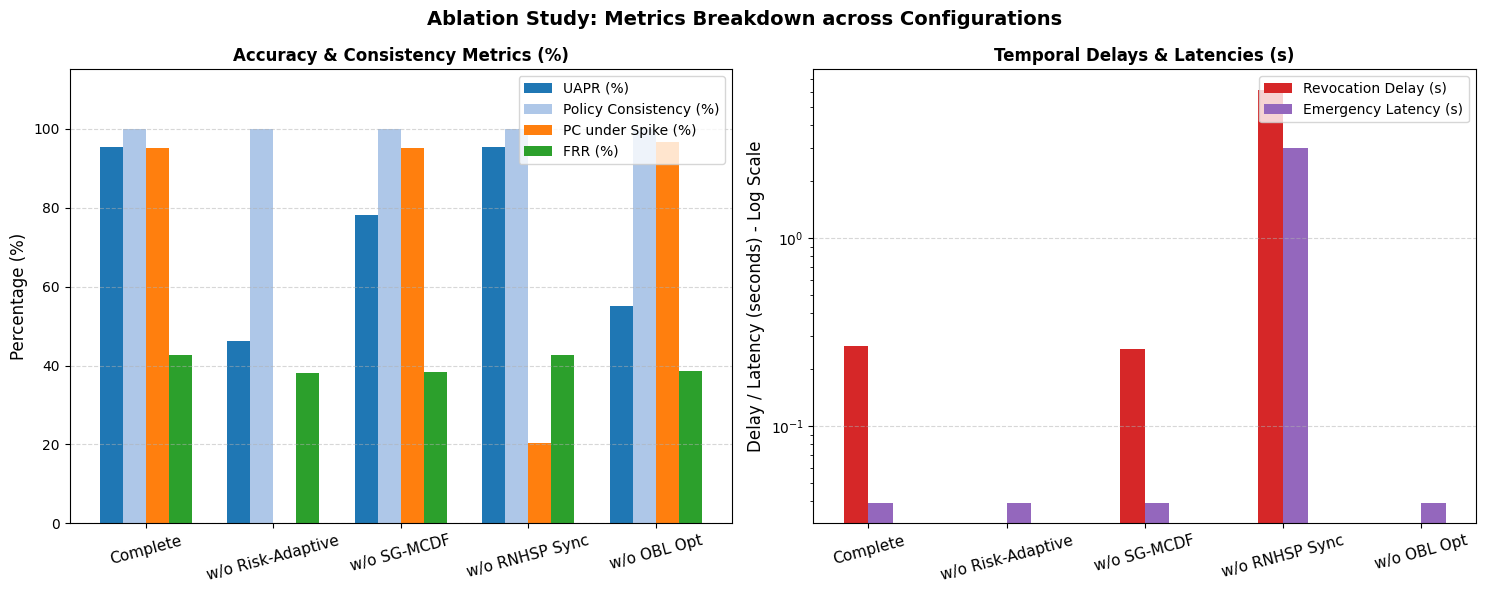

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load the ablation data
df_abl = pd.read_csv("hsc_outputs/table5_ablation.csv")
df_abl.rename(columns={df_abl.columns[0]: "Configuration"}, inplace=True)

# Shorten the configuration names for cleaner plotting labels
short_names = {
    "Complete HyperSecuChain": "Complete",
    "Without risk-adaptive scoring": "w/o Risk-Adaptive",
    "Without SG-MCDF": "w/o SG-MCDF",
    "Without RNHSP synchronization": "w/o RNHSP Sync",
    "Without OBL optimization": "w/o OBL Opt"
}
df_abl["Short_Name"] = df_abl["Configuration"].map(short_names)

# Create a figure with two subplots side-by-side
fig, (ax1,ax2) = plt.subplots(1, 2, figsize=(15, 6))

x = np.arange(len(df_abl))
width = 0.18

# Subplot 1: Percentages (0% to 100%)
ax1.bar(x - 1.5*width, df_abl["UAPR (%)"], width, label="UAPR (%)", color="#1f77b4")
ax1.bar(x - 0.5*width, df_abl["Policy Consistency (%)"], width, label="Policy Consistency (%)", color="#aec7e8")
ax1.bar(x + 0.5*width, df_abl["PC under spike (%)"].fillna(0), width, label="PC under Spike (%)", color="#ff7f0e")
ax1.bar(x + 1.5*width, df_abl["FRR (%)"], width, label="FRR (%)", color="#2ca02c")

ax1.set_ylabel("Percentage (%)", fontsize=12)
ax1.set_ylim(0, 115)
ax1.set_xticks(x)
ax1.set_xticklabels(df_abl["Short_Name"], rotation=15, fontsize=11)
ax1.set_title("Accuracy & Consistency Metrics (%)", fontsize=12, fontweight="bold")
ax1.grid(True, axis="y", linestyle="--", alpha=0.5)
ax1.legend(loc="upper right")

# Subplot 2: Delays / Latencies (Seconds in log-scale)
ax2.bar(x - 0.5*width, df_abl["Revocation Delay (s)"].fillna(0), width, label="Revocation Delay (s)", color="#d62728")
ax2.bar(x + 0.5*width, df_abl["Emergency Latency (s)"].fillna(0), width, label="Emergency Latency (s)", color="#9467bd")

ax2.set_ylabel("Delay / Latency (seconds) - Log Scale", fontsize=12)
ax2.set_yscale("log")
ax2.set_xticks(x)
ax2.set_xticklabels(df_abl["Short_Name"], rotation=15, fontsize=11)
ax2.set_title("Temporal Delays & Latencies (s)", fontsize=12, fontweight="bold")
ax2.grid(True, axis="y", linestyle="--", alpha=0.5)
ax2.legend(loc="upper right")

plt.suptitle("Ablation Study: Metrics Breakdown across Configurations", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

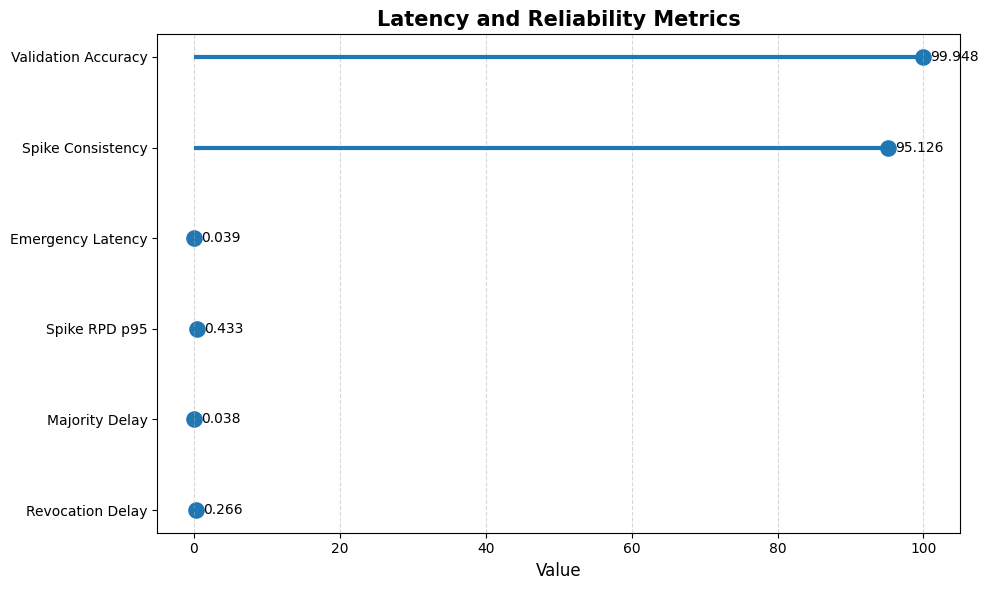

In [34]:
import matplotlib.pyplot as plt

metrics = [
    "Revocation Delay",
    "Majority Delay",
    "Spike RPD p95",
    "Emergency Latency",
    "Spike Consistency",
    "Validation Accuracy"
]

values = [0.266, 0.038, 0.433, 0.039, 95.126, 99.948]

plt.figure(figsize=(10,6))

# Draw horizontal lines
plt.hlines(y=metrics, xmin=0, xmax=values, linewidth=3)

# Draw dots
plt.scatter(values, metrics, s=120)

# Add value labels
for i, v in enumerate(values):
    plt.text(v + 1, i, f"{v:.3f}", va='center', fontsize=10)

plt.xlabel("Value", fontsize=12)
plt.title("Latency and Reliability Metrics", fontsize=15, fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("Latency_Reliability_Lollipop.png", dpi=300)
plt.show()

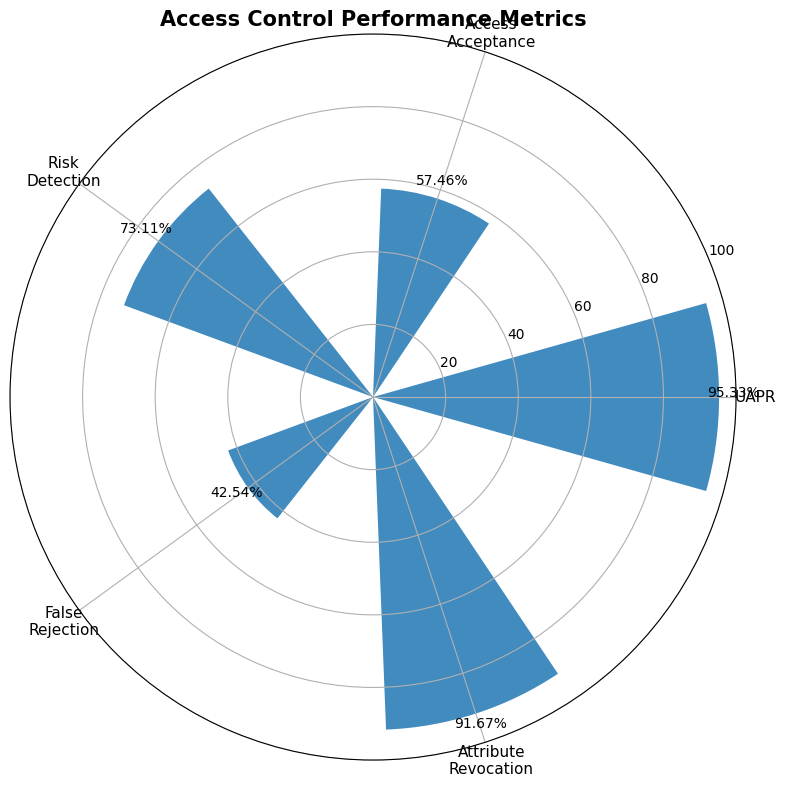

In [35]:
import numpy as np
import matplotlib.pyplot as plt

metrics = [
    "UAPR",
    "Access\nAcceptance",
    "Risk\nDetection",
    "False\nRejection",
    "Attribute\nRevocation"
]

values = [95.33, 57.46, 73.11, 42.54, 91.67]

N = len(metrics)
angles = np.linspace(0, 2*np.pi, N, endpoint=False)

fig = plt.figure(figsize=(8,8))
ax = plt.subplot(111, polar=True)

bars = ax.bar(
    angles,
    values,
    width=0.55,
    bottom=0,
    alpha=0.85
)

ax.set_xticks(angles)
ax.set_xticklabels(metrics, fontsize=11)
ax.set_ylim(0,100)
ax.set_yticks([20,40,60,80,100])

for angle, value in zip(angles, values):
    ax.text(angle, value+4, f"{value:.2f}%", ha='center', fontsize=10)

plt.title("Access Control Performance Metrics", fontsize=15, weight='bold')
plt.tight_layout()
plt.show()

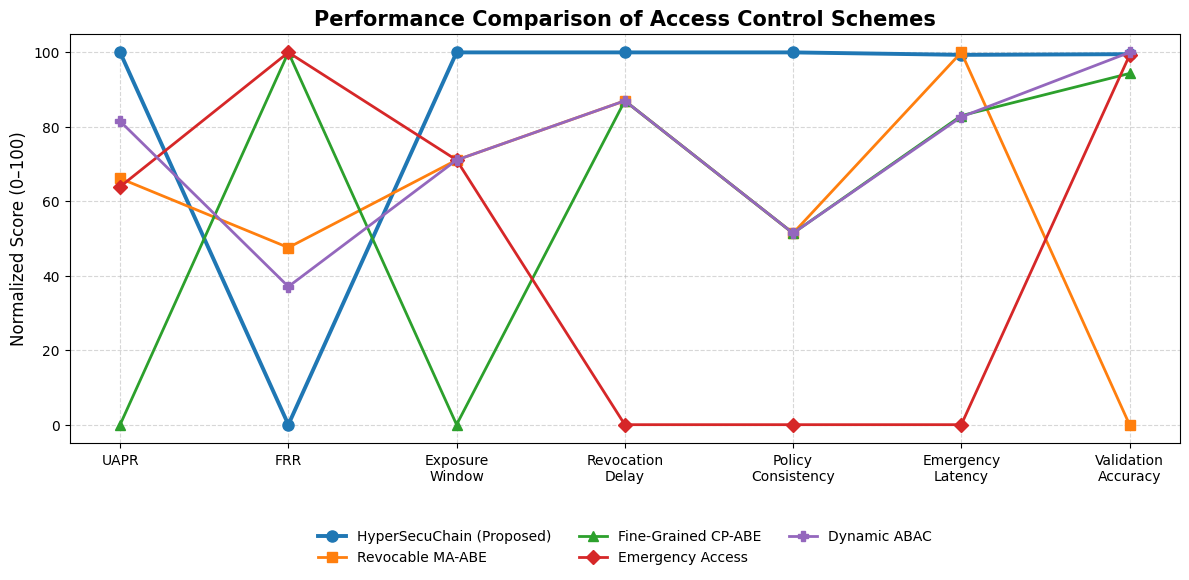

In [37]:
import matplotlib.pyplot as plt
import numpy as np

# Metrics
metrics = [
    "UAPR",
    "FRR",
    "Exposure\nWindow",
    "Revocation\nDelay",
    "Policy\nConsistency",
    "Emergency\nLatency",
    "Validation\nAccuracy"
]

# Data
proposed = [99.41, 6.67, 22.1, 0.32, 94.66, 0.04, 99.43]
revocable = [96.08, 4.81, 46.5, 1.00, 50.90, 0.00, 47.16]   # N/A -> 0
fine_grained = [89.57, 2.76, 106.5, 1.00, 50.90, 1.03, 96.71]
emergency = [95.86, 2.76, 46.5, 5.55, 4.55, 6.06, 99.27]
dynamic_abac = [97.59, 5.22, 46.5, 1.00, 50.90, 1.05, 99.68]

# Normalize each metric column
data = np.array([
    proposed,
    revocable,
    fine_grained,
    emergency,
    dynamic_abac
], dtype=float)

norm = np.zeros_like(data)

for j in range(data.shape[1]):
    col = data[:, j]
    mn = np.min(col)
    mx = np.max(col)

    if mx == mn:
        norm[:, j] = 100
    else:
        norm[:, j] = (col - mn) / (mx - mn) * 100

# Reverse metrics where lower is better
lower_better = [1,2,3,5]

for idx in lower_better:
    norm[:, idx] = 100 - norm[:, idx]

plt.figure(figsize=(12,6))

plt.plot(metrics, norm[0], marker='o', linewidth=2.8, markersize=8,
         label='HyperSecuChain (Proposed)')
plt.plot(metrics, norm[1], marker='s', linewidth=2, markersize=7,
         label='Revocable MA-ABE')
plt.plot(metrics, norm[2], marker='^', linewidth=2, markersize=7,
         label='Fine-Grained CP-ABE')
plt.plot(metrics, norm[3], marker='D', linewidth=2, markersize=7,
         label='Emergency Access')
plt.plot(metrics, norm[4], marker='P', linewidth=2, markersize=7,
         label='Dynamic ABAC')

plt.ylabel("Normalized Score (0–100)", fontsize=12)
plt.title("Performance Comparison of Access Control Schemes", fontsize=15, fontweight='bold')

plt.grid(True, linestyle='--', alpha=0.5)

plt.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, -0.18),
    ncol=3,
    frameon=False
)

plt.tight_layout()
plt.savefig("Performance_Line_Comparison.png", dpi=300)
plt.show()